# Cheaper players who look like ours

Each player-season becomes a short list of numbers. We then look for someone in the same role, in 2025-26, whose list points the same way and whose Transfermarkt value is lower.

## 1. Every player is a vector

A mid-season move is one row: minutes and counting stats are added up, and the club with the most minutes is the team we keep.

Role comes from Transfermarkt. Right-backs and left-backs are fullbacks, the two central midfield roles are one group, wingers and attacking midfielders are another, and strikers stay strikers. If Transfermarkt has no position, we use the first position FBref lists. Goalkeepers are left out.

Counting stats become per-90 rates. We then compare each player with his own role, not with the whole league. A z-score of 0 is typical for that role. Plus one is high. Minus one is low. Only seasons with at least 900 minutes are in the model.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics.pairwise import cosine_similarity

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.features import add_per90, assign_position_group, build_feature_matrix, combine_club_stints, feature_columns
from src.similarity import cosine_similarity_matrix, explain_match, find_similar

pd.set_option("display.max_rows", 20)
pd.set_option("display.width", 120)

LABELS = {
    "goals_per90": "Goals per 90",
    "non_penalty_goals_per90": "Non-penalty goals per 90",
    "assists_per90": "Assists per 90",
    "shots_per90": "Shots per 90",
    "shots_on_target_per90": "Shots on target per 90",
    "crosses_per90": "Crosses per 90",
    "tackles_won_per90": "Tackles won per 90",
    "interceptions_per90": "Interceptions per 90",
    "fouls_committed_per90": "Fouls committed per 90",
    "fouls_drawn_per90": "Fouls drawn per 90",
    "offsides_per90": "Offsides per 90",
    "shot_accuracy": "Shot accuracy",
    "goals_per_shot": "Goals per shot",
}
LEAGUES = {
    "ENG-Premier League": "Premier League",
    "ESP-La Liga": "La Liga",
    "GER-Bundesliga": "Bundesliga",
    "ITA-Serie A": "Serie A",
    "FRA-Ligue 1": "Ligue 1",
}
STRIKER_ROLES = {"Centre-Forward", "Second Striker"}

valued = pd.read_csv(ROOT / "data" / "processed" / "player_season_valued.csv")
combined = combine_club_stints(valued)
positioned = assign_position_group(combined)
rated = add_per90(positioned)
matrix, metadata = build_feature_matrix(rated)
vectors = pd.concat([metadata, matrix], axis=1)
features = feature_columns(vectors)

def season_row(player, season=2526):
    rows = vectors.loc[(vectors["player"] == player) & (vectors["season"] == season)]
    return rows.iloc[0]

def money(value):
    return f"€{value / 1e6:.1f}m"

porro = season_row("Pedro Porro")
raw = rated.loc[(rated["player"] == "Pedro Porro") & (rated["season"] == 2526)].iloc[0]
side_by_side = pd.DataFrame(
    {
        "Per 90": raw[features].astype(float).round(2),
        "Z-score": porro[features].astype(float).round(2),
    }
)
side_by_side.index = [LABELS[name] for name in features]
print(
    f"Pedro Porro, 2025-26, {porro.position_group}, {int(porro.minutes)} minutes, {money(porro.market_value_eur)}"
)
display(side_by_side)


Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot
Pedro Porro, 2025-26, FB, 2796 minutes, €35.0m


,Per 90,Z-score
Goals per 90,0.03,-0.24
Non-penalty goals per 90,0.03,-0.23
Assists per 90,0.06,-0.37
Shots per 90,1.03,0.89
Shots on target per 90,0.26,0.41
Crosses per 90,7.47,2.55
Tackles won per 90,1.61,0.87
Interceptions per 90,1.00,0.08
Fouls committed per 90,1.03,-0.12
Fouls drawn per 90,0.84,-0.25


## 2. Cosine similarity

Two players can have different totals and still have the same shape: lots of crosses, few shots, an average number of tackles. Cosine similarity ignores the size of the profile and measures the angle between the two arrows. 1 means the same shape. 0 means no relationship. Negative means the profiles run in opposite directions.

$$
\cos(\theta) = \frac{A \cdot B}{\|A\| \, \|B\|}
$$

In the code, each row is divided by its length, then the matrix is multiplied by its transpose. That one product is every pairwise cosine. The check below compares it with scikit-learn.

In [2]:
fullbacks = vectors.loc[
    (vectors["position_group"] == "FB") & (vectors["season"] == 2526), features
].to_numpy(dtype=float)
ours = cosine_similarity_matrix(fullbacks)
gap = np.max(np.abs(ours - cosine_similarity(fullbacks)))
print(f"2025-26 fullbacks: {fullbacks.shape[0]} players, {fullbacks.shape[1]} features")
print(f"Largest gap versus sklearn: {gap:.2e}")


2025-26 fullbacks: 256 players, 13 features
Largest gap versus sklearn: 7.77e-16


## 3. Four Spurs searches

Each search stays inside the player's role and inside 2025-26. The player himself is excluded. Everyone left on the list is valued below him. Similarity is the cosine. The last column is the match's value as a percentage of the Spurs player's value.

In [3]:
def show_search(player, **search_kwargs):
    target = season_row(player)
    hits = find_similar(player, vectors=vectors, **search_kwargs)
    table = pd.DataFrame(
        {
            "Player": hits["player"],
            "Team": hits["team"],
            "League": hits["league"].map(LEAGUES).fillna(hits["league"]),
            "Age": hits["age"].round(0).astype("Int64"),
            "Minutes": hits["minutes"].round(0).astype(int),
            "Value": hits["market_value_eur"].map(money),
            "Similarity": hits["similarity"].map(lambda value: f"{value:.2f}"),
            "Value vs target": hits["value_pct"].map(lambda value: f"{value:.0f}%"),
        }
    )
    filters = ", ".join(f"{key}={value}" for key, value in search_kwargs.items()) or "default filters"
    print(
        f"{target.player} ({target.position_group}), {money(target.market_value_eur)}, "
        f"{int(target.minutes)} minutes — {filters}"
    )
    display(table.reset_index(drop=True))

show_search("Pedro Porro")


Pedro Porro (FB), €35.0m, 2796 minutes — default filters


,Player,Team,League,Age,Minutes,Value,Similarity,Value vs target
0,Yanis Zouaoui,Le Havre,Ligue 1,27,2338,€2.5m,0.79,7%
1,Emanuele Valeri,Parma,Serie A,26,2643,€3.0m,0.78,9%
2,Jonathan Clauss,Nice,Ligue 1,32,2530,€4.0m,0.71,11%
3,Hugo Bueno,Wolves,Premier League,22,2366,€12.0m,0.71,34%
4,Przemysław Frankowski,Rennes,Ligue 1,30,1210,€6.0m,0.64,17%
5,Quentin Merlin,Rennes,Ligue 1,23,2533,€15.0m,0.61,43%
6,Christopher Trimmel,Union Berlin,Bundesliga,38,1861,€0.6m,0.61,2%
7,Aarón Martín,Genoa,Serie A,28,2156,€5.0m,0.56,14%
8,David Raum,RB Leipzig,Bundesliga,27,2553,€25.0m,0.56,71%
9,Vladimír Coufal,Hoffenheim,Bundesliga,32,3012,€2.5m,0.53,7%


In [4]:
show_search("João Palhinha")


João Palhinha (CM), €15.0m, 2198 minutes — default filters


,Player,Team,League,Age,Minutes,Value,Similarity,Value vs target
0,Guido Rodríguez,Valencia,La Liga,31,1489,€4.0m,0.70,27%
1,Kervin Arriaga,Levante,La Liga,27,1532,€2.0m,0.64,13%
2,Emirhan İlkhan,Torino,Serie A,21,1001,€6.0m,0.60,40%
3,Casemiro,Manchester Utd,Premier League,33,2571,€6.0m,0.60,40%
4,Suat Serdar,Hellas Verona,Serie A,28,1108,€2.8m,0.58,19%
5,Ryan Christie,Bournemouth,Premier League,30,994,€8.0m,0.56,53%
6,Manu Morlanes,Mallorca,La Liga,26,1765,€2.4m,0.52,16%
7,Jens Stage,Werder Bremen,Bundesliga,28,2460,€14.0m,0.48,93%
8,Yassin Belkhdim,Angers,Ligue 1,23,2135,€7.0m,0.45,47%
9,Grischa Prömel,Hoffenheim,Bundesliga,30,1758,€3.5m,0.41,23%


In [5]:
show_search("Richarlison")


Richarlison (ST), €25.0m, 1964 minutes — default filters


,Player,Team,League,Age,Minutes,Value,Similarity,Value vs target
0,Raúl,Osasuna,La Liga,24,1041,€3.0m,0.73,12%
1,Serge Gnabry,Bayern Munich,Bundesliga,30,1219,€18.0m,0.66,72%
2,Michael Gregoritsch,Augsburg,Bundesliga,31,913,€1.5m,0.62,6%
3,Ayoze Pérez,Villarreal,La Liga,32,1124,€5.0m,0.53,20%
4,Deniz Undav,Stuttgart,Bundesliga,29,2241,€22.0m,0.52,88%
5,Karl Etta Eyong,Levante,La Liga,21,1672,€15.0m,0.52,60%
6,Ermedin Demirović,Stuttgart,Bundesliga,27,1497,€22.0m,0.50,88%
7,Iago Aspas,Celta Vigo,La Liga,37,1140,€1.6m,0.48,6%
8,Wesley Saïd,Lens,Ligue 1,30,1991,€5.0m,0.47,20%
9,Lassine Sinayoko,Auxerre,Ligue 1,25,2770,€10.0m,0.45,40%


In [6]:
show_search("Mohammed Kudus")


Mohammed Kudus (AM_W), €50.0m, 1535 minutes — default filters


,Player,Team,League,Age,Minutes,Value,Similarity,Value vs target
0,Omari Hutchinson,Nottingham,Premier League,21,1688,€30.0m,0.74,60%
1,Franck Honorat,Gladbach,Bundesliga,28,1977,€7.0m,0.74,14%
2,Ángel Pérez,Alavés,La Liga,22,1288,€3.0m,0.72,6%
3,Moses Simon,Paris FC,Ligue 1,30,2001,€7.0m,0.70,14%
4,Bazoumana Touré,Hoffenheim,Bundesliga,19,2308,€40.0m,0.70,80%
5,Danel Sinani,St Pauli,Bundesliga,28,2069,€3.0m,0.69,6%
6,Yankuba Minteh,Brighton,Premier League,21,2391,€45.0m,0.69,90%
7,Ruben Vargas,Sevilla,La Liga,26,1594,€12.0m,0.62,24%
8,Lee Kang-in,Paris SG,Ligue 1,24,1519,€28.0m,0.58,56%
9,Alessio Zerbin,Cremonese,Serie A,26,1646,€2.0m,0.57,4%


## 3b. Thinking like a scout

Raw similarity is not a shortlist. Scouts add constraints: age ceiling, same flank for fullbacks and wide players, and sometimes a league list. Below, Porro is filtered to right-backs aged 27 or under, and Palhinha to midfielders aged 27 or under. The age column is the season age from FBref.


Cheap older players are cheap partly because of age, not just because the market has mispriced their output. A €1m 35-year-old can look "cheaper" than a €30m 25-year-old with the same stat shape, but that is not the same as **undervalued**. The value model we build later will separate fee from performance; this notebook only filters on market value and similarity.


In [7]:
show_search("Pedro Porro", max_age=27, same_side=True)


Pedro Porro (FB), €35.0m, 2796 minutes — max_age=27, same_side=True


,Player,Team,League,Age,Minutes,Value,Similarity,Value vs target
0,Andrei Ratiu,Rayo Vallecano,La Liga,27,2807,€18.0m,0.38,51%
1,Lorenz Assignon,Stuttgart,Bundesliga,25,1094,€9.0m,0.35,26%
2,Fodé Doucouré,Le Havre,Ligue 1,24,1239,€2.0m,0.34,6%
3,Lilian Raolisoa,Angers,Ligue 1,25,1966,€4.0m,0.30,11%
4,Julian Ryerson,Dortmund,Bundesliga,27,2266,€25.0m,0.29,71%
5,Tommaso Barbieri,Cremonese,Serie A,22,1707,€3.8m,0.28,11%
6,Jesús Areso,Athletic Club,La Liga,26,1506,€5.0m,0.26,14%
7,Iglesias,Getafe,La Liga,27,3185,€5.0m,0.19,14%
8,Trai Hume,Sunderland,Premier League,23,3036,€22.0m,0.17,63%
9,Lamine Sy,Auxerre,Ligue 1,22,1536,€2.5m,0.17,7%


In [8]:
show_search("João Palhinha", max_age=27)


João Palhinha (CM), €15.0m, 2198 minutes — max_age=27


,Player,Team,League,Age,Minutes,Value,Similarity,Value vs target
0,Kervin Arriaga,Levante,La Liga,27,1532,€2.0m,0.64,13%
1,Emirhan İlkhan,Torino,Serie A,21,1001,€6.0m,0.60,40%
2,Manu Morlanes,Mallorca,La Liga,26,1765,€2.4m,0.52,16%
3,Yassin Belkhdim,Angers,Ligue 1,23,2135,€7.0m,0.45,47%
4,Jens Castrop,Gladbach,Bundesliga,22,1584,€10.0m,0.41,67%
5,Tommaso Pobega,Bologna,Serie A,26,1434,€8.0m,0.35,53%
6,András Schäfer,Union Berlin,Bundesliga,26,1421,€4.5m,0.35,30%
7,Patrizio Masini,Genoa,Serie A,24,1413,€4.2m,0.32,28%
8,Jurgen Ekkelenkamp,Udinese,Serie A,25,2186,€10.0m,0.29,67%
9,Nikolas Nartey,Stuttgart,Bundesliga,25,1256,€10.0m,0.29,67%


## 4. Porro against his three closest matches

Each bar is a z-score among fullbacks. The zero line is an average fullback. Bars to the right mean he does more of that than a typical fullback.

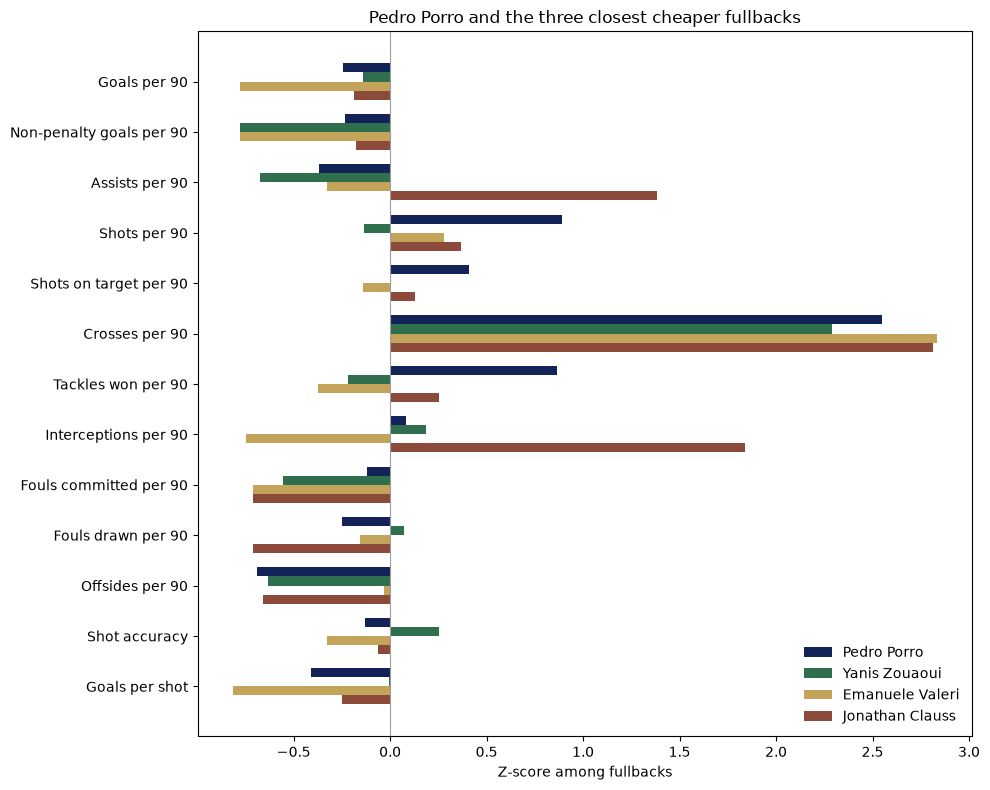

Where Porro and Yanis Zouaoui are closest, and where they split


,kind,feature,z_a,z_b,abs_diff
0,alike,Offsides per 90,-0.69,-0.63,0.06
1,alike,Goals per 90,-0.24,-0.14,0.10
2,alike,Interceptions per 90,0.08,0.19,0.11
3,different,Tackles won per 90,0.87,-0.22,1.09
4,different,Shots per 90,0.89,-0.14,1.03
5,different,Non-penalty goals per 90,-0.23,-0.78,0.54


In [9]:
porro_matches = find_similar("Pedro Porro", vectors=vectors)
compared = [("Pedro Porro", "Tottenham")] + list(
    porro_matches.head(3)[["player", "team"]].itertuples(index=False, name=None)
)
colors = ["#132257", "#2F6F4E", "#C4A35A", "#8C4A3A"]
y = np.arange(len(features))
height = 0.18

fig, ax = plt.subplots(figsize=(10, 8))
for i, (name, team) in enumerate(compared):
    row = vectors.loc[
        (vectors["player"] == name) & (vectors["team"] == team) & (vectors["season"] == 2526)
    ].iloc[0]
    offset = (i - 1.5) * height
    ax.barh(y + offset, row[features].to_numpy(dtype=float), height=height, color=colors[i], label=name)

ax.set_yticks(y)
ax.set_yticklabels([LABELS[name] for name in features])
ax.axvline(0, color="#9aa0a6", linewidth=0.8)
ax.set_xlabel("Z-score among fullbacks")
ax.set_title("Pedro Porro and the three closest cheaper fullbacks")
ax.legend(loc="lower right", frameon=False)
ax.invert_yaxis()
fig.tight_layout()
plt.show()

closest = porro_matches.iloc[0]["player"]
gaps = explain_match("Pedro Porro", closest, vectors=vectors)
gaps["feature"] = gaps["feature"].map(LABELS)
print(f"Where Porro and {closest} are closest, and where they split")
display(gaps.round(2))


## 5. Sanity checks

Two checks that the model is not matching noise.

(a) Pedro Porro's 2025-26 vector should be closer to his own 2024-25 vector than to any other fullback from 2024-25.

(b) Richarlison's ten closest cheaper matches should mostly be strikers on Transfermarkt, not wingers who slipped into the group through the FBref fallback.

In [10]:
target = season_row("Pedro Porro", 2526)
last_season = vectors.loc[
    (vectors["position_group"] == target["position_group"]) & (vectors["season"] == 2425)
].reset_index(drop=True)
block = np.vstack(
    [target[features].to_numpy(dtype=float), last_season[features].to_numpy(dtype=float)]
)
scores = cosine_similarity_matrix(block)[0, 1:]
best = last_season.iloc[int(np.argmax(scores))]
same_player = best["player"] == target["player"] and best["birth_year"] == target["birth_year"]
print(
    f"(a) Closest 2024-25 fullback to Porro 2025-26: {best['player']} ({best['team']}), "
    f"similarity {scores.max():.2f}"
)
print("PASS" if same_player else "FAIL")

richarlison = find_similar("Richarlison", n=10, vectors=vectors)
roles = richarlison.merge(
    vectors.loc[vectors["season"] == 2526, ["player", "team", "sub_position"]],
    on=["player", "team"],
    how="left",
)
striker_count = int(roles["sub_position"].isin(STRIKER_ROLES).sum())
print(f"(b) {striker_count} of 10 Richarlison matches are Transfermarkt strikers")
print(roles["sub_position"].value_counts().to_string())
print("PASS" if striker_count >= 6 else "FAIL")


(a) Closest 2024-25 fullback to Porro 2025-26: Pedro Porro (Tottenham), similarity 0.76
PASS
(b) 10 of 10 Richarlison matches are Transfermarkt strikers
sub_position
Centre-Forward    8
Second Striker    2
PASS


## 6. Limitations

There is no expected goals, and no passing. FBref no longer publishes the Opta tables, so key passes, progressive passes, and pass completion are not in this model.

There is no dribbling or take-on data either, so wide attackers like Kudus are matched on shooting and crossing, not ball-carrying.

A per-90 number in Ligue 1 is treated the same as one in the Premier League. League strength is not adjusted.

The values are Transfermarkt's figures from June 2026, not a live price.
